In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

m,cm=1,0.01
class Detector():
    def __init__(self, R=2*m,N=40,r=10*cm, prob=0.5):
        self.R=R
        self.N=N
        self.r=r
        self.prob=prob
        self.PMTArray=self.uniform_distribution()
    def uniform_distribution(self):
        # реализовано детерминистическое заполнение по спирали фибоначчи вместо random.uniform
        i = np.arange(self.N)
        golden_ratio = (1 + np.sqrt(5)) / 2
        cosTheta = 1 - 2 * (i + 0.5) / self.N
        sinTheta = np.sqrt(1 - cosTheta*cosTheta)
        phi = 2 * np.pi * i / golden_ratio
        return self.R * np.array([sinTheta * np.cos(phi),sinTheta * np.sin(phi),cosTheta])
        
        
    #Так как радиус ФЭУ по сравнению с радиусом сферы мал, предполагается, что ФЭУ целиком лежит на поверхности сферы. 
    #Далее, в силу того, что ФЭУ имеют форму окружности ставится условие на угол между вектором направления 
    #точки и радиус-вектором центра окружности ФЭУ (alpha<alpha_max, где alpha_max \approx r/R ) 
    def IsInPMT(self, point:np.ndarray):
        cosMax=np.cos(self.r/self.R)
        cosCheck = (point.T @ self.PMTArray) / (self.R ** 2)
        return np.any(cosCheck>cosMax, axis=1)



#тест на проверку работы метода IsInPMT
def test_IsInPMT(N:int):
    D1=Detector()
    phi=np.random.uniform(0,2*np.pi, N)
    cosTheta=np.random.uniform(-1,1,N)
    sinTheta=np.sqrt(1-cosTheta*cosTheta)
    PointArray=D1.R*np.array([sinTheta*np.cos(phi),sinTheta*np.sin(phi), cosTheta])
    registered=np.sum(D1.IsInPMT(PointArray))
    return registered

def test_IsUniformlyDistributed():
    D1=Detector(2,2000)
    x,y,z=D1.PMTArray
    CosTheta = z
    Phi = np.arctan2(y, x)   
    Phi = (Phi + 2*np.pi) % (2*np.pi)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))    
    sns.histplot(CosTheta, bins=40, stat='density', kde=False, color='skyblue', edgecolor='black',label='CosTheta',ax=axes[0])
    sns.histplot(Phi, bins=40, stat='density', kde=False, color='skyblue', edgecolor='black',label='Phi',ax=axes[1])
    axes[0].legend()
    axes[1].legend()
    plt.tight_layout()
    plt.show()
    

N=10**4
print (f"registered: {test_IsInPMT(N)} out of {N}")

registered: 235 out of 10000


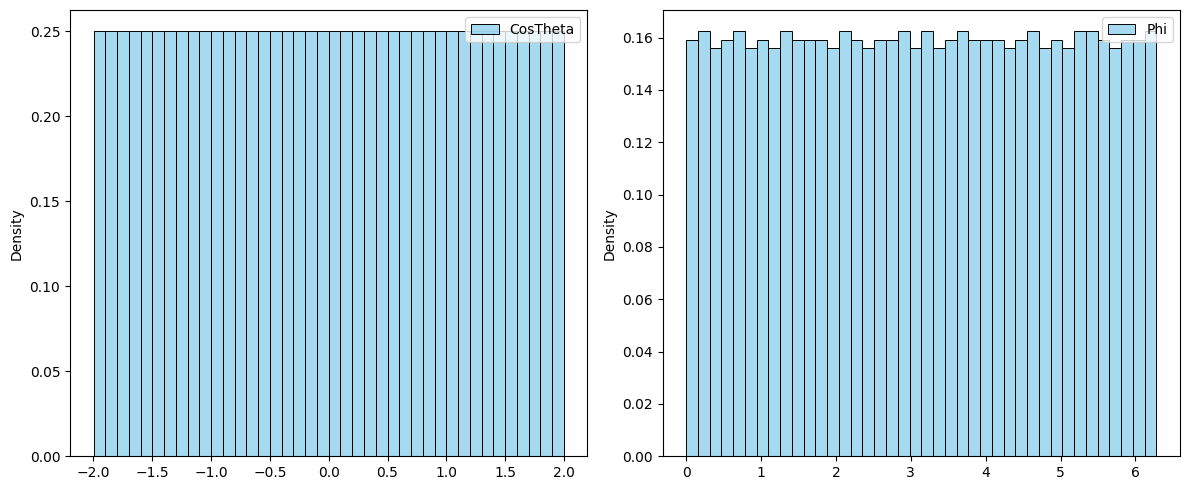

In [12]:
test_IsUniformlyDistributed() 